## Presentado por:

## Esteban Garcia Otalvaro

## Introducción al análisis frecuencial de señales

In [37]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import welch
from scipy.io import loadmat

## Primero se probarán los códigos entregados en la guía para un enetendiiento más profundo de la práctica.

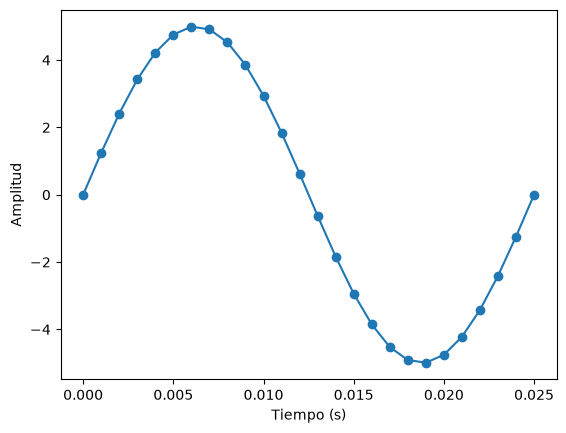

In [38]:
# Código base de la guía para entender la práctica
Fo = 40 # Frecuencia fundamental de la señal
Tp = 1/Fo # Periodo de la señal
Fs = 1000 # Frecuencia de muestreo
T = 1/Fs # Periodo de muestreo
t = np.arange(0, Tp+T, T) # Tiempo para un ciclo de la señal con duración de Tp más una muestra T
A = 5
x = A*np.sin(2*np.pi*Fo*t)
plt.plot(t, x, marker='o')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.show()


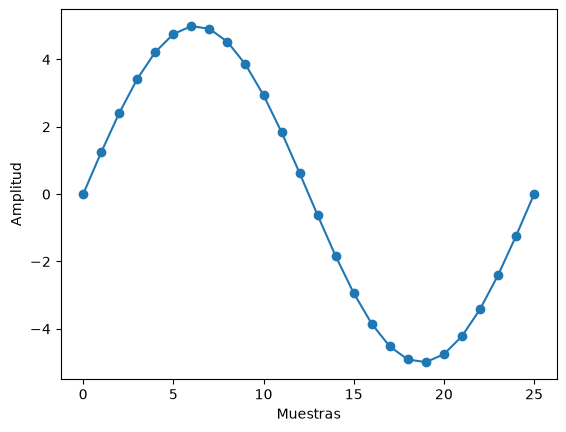

In [39]:
#Una manera alternativa de crear la señal 𝑥(𝑛) sería:
fo = Fo/Fs
n = np.arange(0, len(t))
x1 = A*np.sin(2*np.pi*fo*n)
plt.plot(n, x1, marker='o')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()

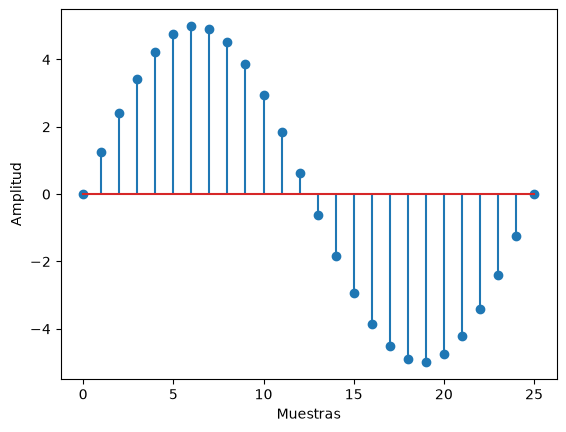

In [40]:
#a) Compruebe que los valores de las primeras cinco muestras son los mismos

plt.stem(n, x1)
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()


In [41]:
energia = sum(x**2)
potencia = energia/(len(t)-1)
#El valor cuadrático medio es la raíz cuadrada de la potencia:
rms = np.sqrt(potencia)
#Para hallar la energía, así como la potencia media de la señal considerando 10 ciclos de la sinusoide (250ms):
t10 = np.arange(0,10*Tp+T,T)
x10 = A*np.sin(2*np.pi*Fo*t10)
energia10 = sum(x10**2)
potencia10 = energia10/(len(t10)-1)
rms10 = np.sqrt(potencia10)


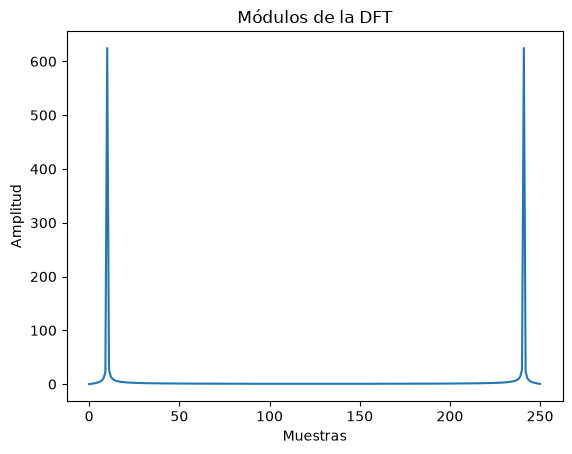

In [42]:
X10 = np.fft.fft(x10) #calcula en Python mediante el comando np.fft.fft
plt.plot(abs(X10))
plt.title('Módulos de la DFT')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()

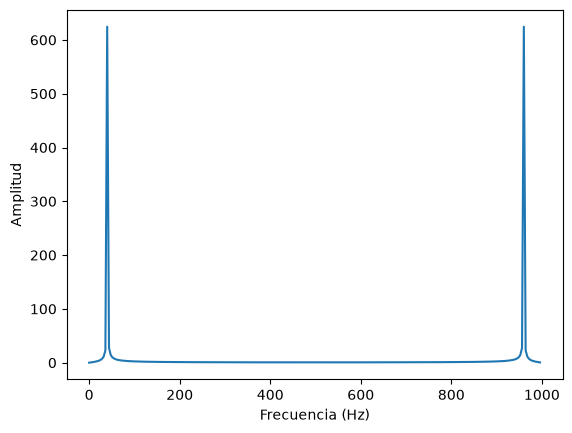

In [43]:
N = len(X10)
F = np.arange(0,N)*Fs/N
plt.plot(F,abs(X10))
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.show()

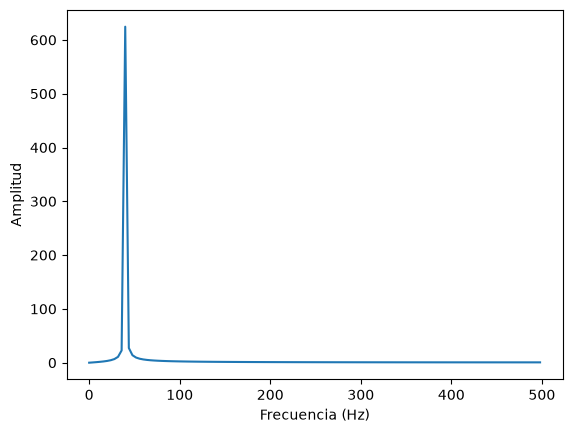

In [44]:
#Frecuencia Midad o Frecuencia de Nyquist
Nmitad = int(np.ceil(N/2))
Fmitad = np.arange(0,Nmitad)*Fs/N
X10mitad = X10[0:Nmitad]
plt.plot(Fmitad,abs(X10mitad))
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.show()

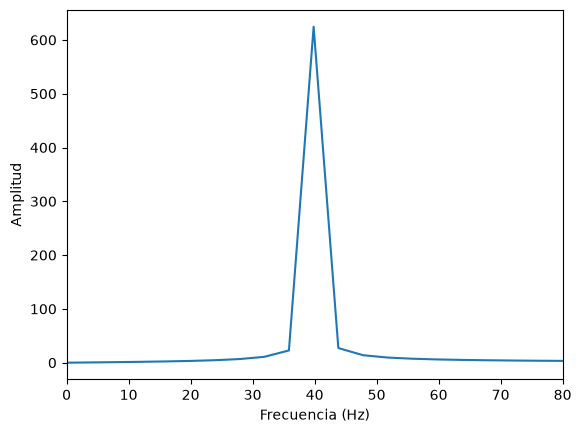

In [45]:
# Componente frecuencial se encuentra ubicada a 40 Hz
plt.plot(Fmitad,abs(X10mitad))
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.xlim(0,80)
plt.show()

In [46]:
"""Periodograma de Welch
Método de Welch donde calcula la densidad espectral de potencia en una ventana que se desplaza a lo largo de la señal.
y finalmente sepromedian los espectros de potencia para obtener un periodograma de Welch."""
#@title Default title text
#importamos la rutina de welch
from scipy.signal import welch as pwelch

#%% USANDO WELCH
fs = 1000 # frecuencia de muestreo
nperseg = 2000 #ancho de la ventana
noverlap = int(nperseg/2) #solapamiento de las ventanas
f, Pxx = pwelch(senal[0,:], fs, 'hanning', nperseg, noverlap)
#graficamos frecuencia vs potencia
plt.stem(f, Pxx)
plt.xlabel('Frecuencia')
plt.ylabel('Potencia')
plt.xlim([0, 50]) #rango para el eje X
plt.show()



NameError: name 'senal' is not defined

## Desarrollo de la práctica

**4.1 Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40,
80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal,
y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. (10%)**

El teorema de Nyquist establece que la frecuencia de muestreo mínima debe ser mayor al doble de la frecuencia más alta presente en la señal ($F_s > 2F_{\max}$), en la práctica tomar exactamente esa tasa resulta insuficiente para representar adecuadamente la forma de la onda. Esto se debe a que se estarían tomando solo dos muestras por ciclo de la señal de mayor frecuencia, con lo que no es posible capturar con precisión la morfología sinusoidal ni sus variaciones de fase o amplitud (pudiendo incluso caer en los cruces por cero). Por esta razón, se recomienda utilizar una frecuencia de muestreo al menos 10 veces mayor que la frecuencia más alta de interés ($F_s = 1600\text{ Hz}$), lo que garantiza una mayor cantidad de datos por ciclo y, por tanto, una reconstrucción más fiel y visualmente clara de las señales [1].

Frecuencia de muestreo mínima (Nyquist): 320 Hz
Frecuencia de muestreo utilizada: 1600 Hz


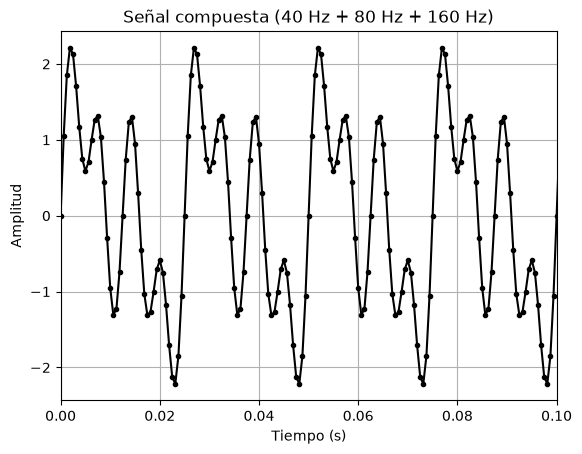

In [51]:
# Definición de frecuencias de muestreo
F_max = 160
Fs_min = 2 * F_max       # Frecuencia mínima de Nyquist: 320 Hz
Fs = F_max * 10          # Frecuencia adecuada elegida: 1600 Hz
T = 1 / Fs               # Periodo de muestreo
A = 1

print(f"Frecuencia de muestreo mínima (Nyquist): {Fs_min} Hz")
print(f"Frecuencia de muestreo utilizada: {Fs} Hz")

# Vector de tiempo para 10 periodos de la señal fundamental (40 Hz -> Tp = 0.025 s)
duration = 10 * (1 / 40) # 0.25 segundos
t = np.arange(0, duration, T)

# Señal de 40 Hz
Fo1 = 40
x1 = A * np.sin(2 * np.pi * Fo1 * t)

# Señal de 80 Hz
Fo2 = 80
x2 = A * np.sin(2 * np.pi * Fo2 * t)

# Señal de 160 Hz
Fo3 = 160
x3 = A * np.sin(2 * np.pi * Fo3 * t)

# Suma de las tres componentes
x = x1 + x2 + x3

# Gráfica en el dominio del tiempo (zoom a los primeros 0.1 s = 4 ciclos)
plt.plot(t, x, marker='o', markersize=3, color='black')
plt.title('Señal compuesta (40 Hz + 80 Hz + 160 Hz)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.xlim(0, 0.1)
plt.show()

**4.2 Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia.
Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos
de la señal). (10%)**


**4.3 Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier.
Aplíquelo a la señal anterior. (10%)**

**4.4 ¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? (10%)**
F1 = np.fft.fft(x);

F2 = np.zeros((len(F1)));

F2[9:13] = F1[9:13];

xr = np.fft.ifft(F2);

fig = plt.figure()

ax = fig.add_subplot(111)

ax.plot(t, np.real(xr))

Introducción al análisis frecuencial de señales Bioseñales y sistemas

ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');

plt.show()

**Extraiga de manera similar cada una de las componentes de la señal.**

**4.5 Cree una función que calcule manualmente el periodograma de Welch de una señal discreta
(usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales
construidas anteriormente.**


**4.6 El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de
muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas
de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que
se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de
Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning,
y justificar la elección del solapamiento y el ancho de la ventaja) (25%). Compare el
método de la librería con la función creada en el punto anterior.**

**4.7 Realice un análisis de frecuencia a través del periodograma de welch de una señal de EKG
de un paciente Sano y otra de un paciente con alguna condición cardiaca que en el proyecto
1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al
azar. Realice un análisis comparativo de las señales según lo que le indiquen los
periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el
ancho de la ventana) (25%)**


**4.8 Conclusiones y referencias (10%)**

## Conclusiones

## Referencias Bibliográficas

[1]Siemens Simcenter. (2020, agosto 29). Digital Signal Processing: Sampling Rates, Bandwidth, Spectral Lines, and more. Siemens Community. https://community.sw.siemens.com/s/article/digital-signal-processing-sampling-rates-bandwidth-spectral-lines-and-more